# 🫛 🥬 Bin Dataset — End-to-End Image Classification Project

**A step-by-step deep learning project (same workflow as the Gender Detection / Digit Recognition notebooks)**

We build a deep learning model that classifies each image in the **Bin dataset** into its class. The notebook is written to **adapt automatically** to your data: it reads the class names from the folder names, so it works for **binary or multi-class** datasets and for layouts like `class/img.jpg` or `train/class/img.jpg`.

Workflow:

1. **EDA** — load & explore the raw images, check class balance and data quality
2. **Preprocessing** — train/validation/test generators with augmentation on the training set only
3. **Model Building** — baseline, two CNN configurations **and** a MobileNetV2 transfer-learning model, compared side by side
4. **Evaluation** — comparison table, confusion matrix, per-class report, new-image prediction
5. **Conclusion** — findings, limitations, next steps

**For high accuracy and low validation loss:** BatchNorm + Dropout + L2, augmentation on training data only, class weights for imbalance, `EarlyStopping` / `ReduceLROnPlateau` on `val_loss` with best-weights restore, and a pretrained backbone trained in two phases (frozen → fine-tuned).

## 0. Load the dataset
Set **`DATA_PATH`** to your extracted dataset folder. If you only have a zip file, set `ZIP_PATH` and it will be extracted for you.

In [2]:
import os, zipfile, pathlib

# ---------------- CONFIG ----------------
DATA_PATH = r"C:\Users\Girish M\Downloads\Bin-dataset-3"      # folder that contains the class folders (or train/test folders)
ZIP_PATH  = None                 # e.g. "Bin-dataset-3.zip"  (leave None if already extracted)
# ----------------------------------------

if ZIP_PATH and not os.path.isdir(DATA_PATH):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_PATH)

path = DATA_PATH
assert os.path.isdir(path), f"Folder not found: {path} - update DATA_PATH."
print("Path to dataset files:", path)
print(os.listdir(path))

Path to dataset files: C:\Users\Girish M\Downloads\Bin-dataset-3
['Data', 'PRAICP-1006-Bin_images_classification_in_3_cat.docx']


**Build a dataframe of image path + label**

The label is the name of the image's parent folder. Pre-made `train / val / valid / test` folders are ignored as labels (we pool everything and make our own stratified split, as in the previous projects).

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif", ".tif", ".tiff"}
SPLIT_NAMES = {"train", "training", "val", "valid", "validation", "test", "testing", "images", "data", "dataset"}

data = []
for p in pathlib.Path(path).rglob("*"):
    if p.suffix.lower() in IMG_EXTS and not p.name.startswith("."):
        parents = [x for x in p.parent.relative_to(path).parts if x.lower() not in SPLIT_NAMES]
        if parents:                           # nearest non-split folder = class
            data.append([str(p), parents[-1]])

df = pd.DataFrame(data, columns=["image_path", "label"])
assert len(df) > 0, "No labelled images found - check DATA_PATH and the folder structure."
classes = sorted(df["label"].unique())
n_classes = len(classes)
print(f"{len(df)} images | {n_classes} classes: {classes}")
df.head()

1295 images | 3 classes: ['angular_leaf_spot', 'bean_rust', 'healthy']


,image_path,label
0,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,angular_leaf_spot
1,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,angular_leaf_spot
2,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,angular_leaf_spot
3,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,angular_leaf_spot
4,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,angular_leaf_spot


## 1. Exploratory Data Analysis (EDA)

**Visualize sample images from each class**

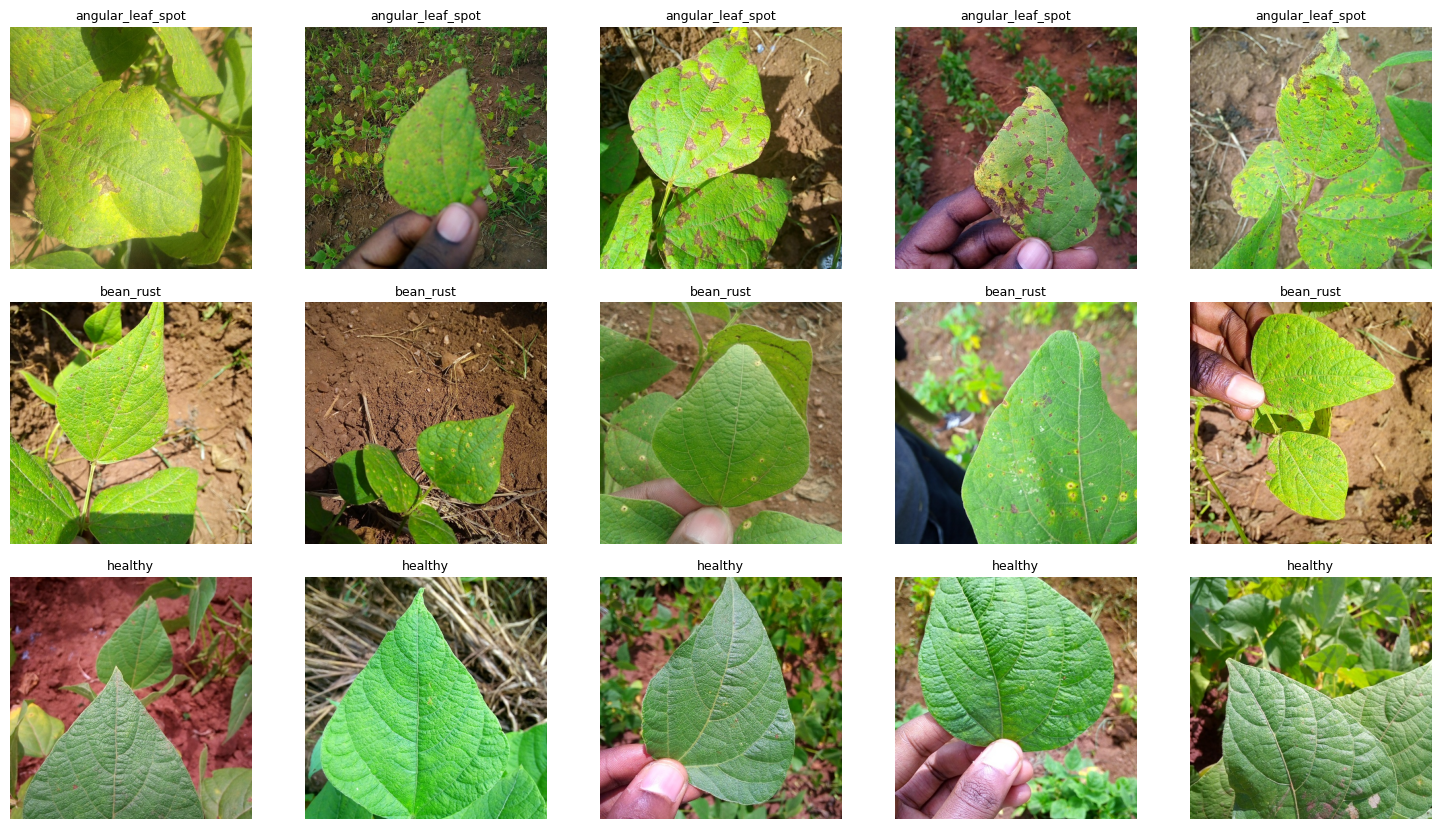

In [4]:
per_class = 5
fig, axes = plt.subplots(n_classes, per_class, figsize=(3*per_class, 2.8*n_classes), squeeze=False)
for r, cls in enumerate(classes):
    samples = df[df["label"] == cls]["image_path"]
    samples = samples.sample(min(per_class, len(samples)), random_state=42)
    for c in range(per_class):
        axes[r, c].axis("off")
        if c < len(samples):
            axes[r, c].imshow(Image.open(samples.iloc[c]).convert("RGB"))
            axes[r, c].set_title(cls, fontsize=9)
plt.tight_layout(); plt.show()

**Number of images in each class (class balance)**

label
angular_leaf_spot    432
bean_rust            436
healthy              427
Name: count, dtype: int64


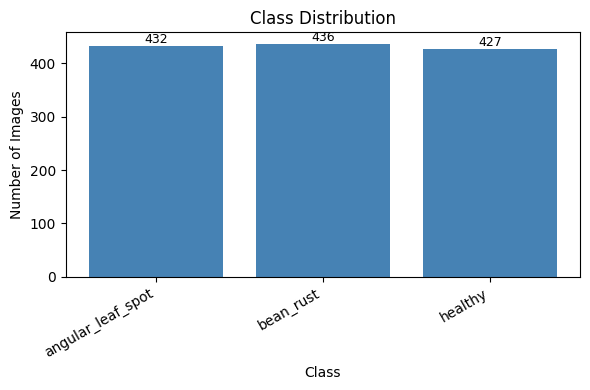


Max class size: 436 | Min class size: 427
Imbalance ratio (max/min): 1.02


In [5]:
class_counts = df["label"].value_counts().sort_index()
print(class_counts)

plt.figure(figsize=(max(6, n_classes*1.2), 4))
bars = plt.bar(class_counts.index.astype(str), class_counts.values, color="steelblue")
plt.xlabel("Class"); plt.ylabel("Number of Images"); plt.title("Class Distribution")
plt.xticks(rotation=30, ha="right")
for bar, value in zip(bars, class_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), str(value), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

print("\nMax class size:", class_counts.max(), "| Min class size:", class_counts.min())
print("Imbalance ratio (max/min):", round(class_counts.max() / class_counts.min(), 2))
assert class_counts.min() >= 3, "A class has fewer than 3 images - a stratified split is not possible."

**Data quality check: corrupt files and outlier image dimensions**

We open every image to flag corrupt/truncated files and look at the distribution of sizes and colour modes.

In [6]:
from collections import Counter

corrupt_files, sizes, modes = [], [], []
for img_path in df["image_path"]:
    try:
        with Image.open(img_path) as im:
            im.verify()
        with Image.open(img_path) as im:
            sizes.append(im.size); modes.append(im.mode)
    except Exception as e:
        corrupt_files.append((img_path, str(e)))

print(f"Total images scanned: {len(sizes) + len(corrupt_files)}")
print(f"Corrupt / unreadable files found: {len(corrupt_files)}")
for f, err in corrupt_files[:10]:
    print(" -", f, "->", err)

size_counts = Counter(sizes)
print("\nImage size distribution (top 5):")
for sz, cnt in size_counts.most_common(5):
    print(" ", sz, ":", cnt)
print("\nImage colour-mode distribution:", dict(Counter(modes)))

widths, heights = zip(*sizes)
print(f"Width  min/median/max: {min(widths)}/{int(np.median(widths))}/{max(widths)}")
print(f"Height min/median/max: {min(heights)}/{int(np.median(heights))}/{max(heights)}")
print("\n⚠️ Multiple sizes - all images are resized consistently in preprocessing." if len(size_counts) > 1
      else "\n✅ All images share a single consistent size.")

if corrupt_files:
    bad = {f for f, _ in corrupt_files}
    df = df[~df["image_path"].isin(bad)].reset_index(drop=True)
    print("Removed corrupt files. Remaining images:", len(df))

# Duplicate check (same file content in several places would leak between splits)
import hashlib
df["_hash"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df["image_path"]]
dups = df.duplicated("_hash").sum()
print(f"Exact duplicate images: {dups}")
if dups:
    df = df.drop_duplicates("_hash").reset_index(drop=True)
    print("Dropped duplicates. Remaining images:", len(df))
df = df.drop(columns="_hash")

Total images scanned: 1295
Corrupt / unreadable files found: 0

Image size distribution (top 5):
  (500, 500) : 1295

Image colour-mode distribution: {'RGB': 1295}
Width  min/median/max: 500/500/500
Height min/median/max: 500/500/500

✅ All images share a single consistent size.
Exact duplicate images: 0


**Shuffle data**

In [7]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.head()

,image_path,label
0,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,healthy
1,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,angular_leaf_spot
2,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,healthy
3,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,healthy
4,C:\Users\Girish M\Downloads\Bin-dataset-3\Data...,healthy


**Train / Validation / Test split (70 / 15 / 15, stratified)**

In [8]:
from sklearn.model_selection import train_test_split

train_data, temp_data = train_test_split(df, test_size=0.3, random_state=42, stratify=df["label"])
val_data, test_data   = train_test_split(temp_data, test_size=0.5, random_state=42, stratify=temp_data["label"])

train_data = train_data.reset_index(drop=True)
val_data   = val_data.reset_index(drop=True)
test_data  = test_data.reset_index(drop=True)

print(f"Training set size:   {len(train_data)}")
print(f"Validation set size: {len(val_data)}")
print(f"Test set size:       {len(test_data)}")

Training set size:   906
Validation set size: 194
Test set size:       195


## 2. Preprocessing

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

batch_size = 32
img_height = 224
img_width  = 224

**Separate generators for training vs. validation/test data**

Augmentation is applied **only to the training set**; validation and test stay unmodified so metrics are trustworthy. Rotation, shift, zoom, flip and brightness changes are used because a bin/object photo is still the same class when taken from a slightly different angle, distance or lighting. (If any class depends on left/right orientation, set `horizontal_flip=False`.)

In [11]:
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    brightness_range=(0.8, 1.2),
    horizontal_flip=True,
    fill_mode="nearest",
)
val_test_datagen = ImageDataGenerator(rescale=1.0/255)

In [12]:
# train generator
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_data, x_col="image_path", y_col="label",
    target_size=(img_height, img_width), batch_size=batch_size,
    class_mode="categorical", shuffle=True, seed=SEED)

Found 906 validated image filenames belonging to 3 classes.


In [13]:
# validation generator (no augmentation, no shuffle)
validation_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_data, x_col="image_path", y_col="label",
    target_size=(img_height, img_width), batch_size=batch_size,
    class_mode="categorical", shuffle=False)

Found 194 validated image filenames belonging to 3 classes.


In [14]:
# test generator (no augmentation, no shuffle so predictions line up with true labels)
test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_data, x_col="image_path", y_col="label",
    target_size=(img_height, img_width), batch_size=batch_size,
    class_mode="categorical", shuffle=False)

class_labels = [k for k, v in sorted(train_generator.class_indices.items(), key=lambda kv: kv[1])]
print("Class indices:", train_generator.class_indices)

Found 195 validated image filenames belonging to 3 classes.
Class indices: {'angular_leaf_spot': 0, 'bean_rust': 1, 'healthy': 2}


In [15]:
for name, gen in [("Train", train_generator), ("Validation", validation_generator), ("Test", test_generator)]:
    image_batch, labels_batch = next(iter(gen))
    print(f"{name} Shape: {image_batch.shape} (Batches = {len(gen)})")
    print(f"{name} Label Shape: {labels_batch.shape}\n")

Train Shape: (32, 224, 224, 3) (Batches = 29)
Train Label Shape: (32, 3)

Validation Shape: (32, 224, 224, 3) (Batches = 7)
Validation Label Shape: (32, 3)

Test Shape: (32, 224, 224, 3) (Batches = 7)
Test Label Shape: (32, 3)



**Preview augmented training images**

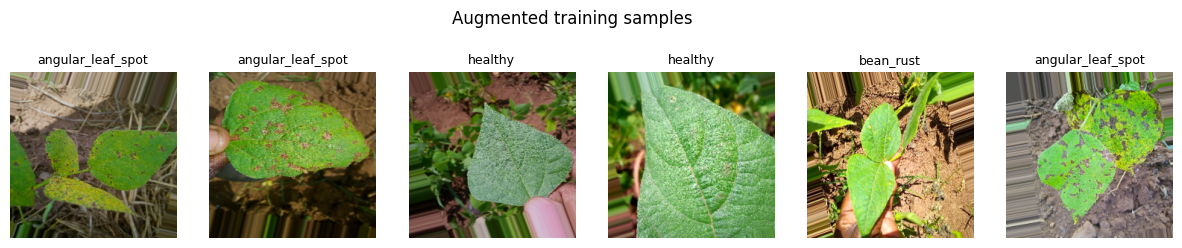

In [16]:
images, labels = next(iter(train_generator))
plt.figure(figsize=(15, 3))
for i in range(6):
    plt.subplot(1, 6, i+1)
    plt.imshow(np.clip(images[i], 0, 1)); plt.title(class_labels[int(np.argmax(labels[i]))], fontsize=9); plt.axis("off")
plt.suptitle("Augmented training samples"); plt.show()

## 3. Model Building

Four models are trained so the final choice is backed by evidence:

1. **Baseline — Feed-Forward (Dense) Network**
2. **CNN v1** — plain CNN (3 Conv blocks + Dense head)
3. **CNN v2** — deeper regularized CNN (double conv blocks, BatchNorm, Dropout, L2, Global Average Pooling)
4. **CNN v3 — Transfer Learning (MobileNetV2)** — ImageNet backbone, trained frozen first and then fine-tuned

Every model monitors **`val_loss`** with `EarlyStopping` + `ReduceLROnPlateau` and restores the best epoch's weights.

In [17]:
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight

# Class weights (handles class imbalance)
y_idx = train_generator.classes
cw = compute_class_weight("balanced", classes=np.arange(n_classes), y=y_idx)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("class_weight:", {class_labels[i]: round(w, 2) for i, w in class_weight.items()})

METRICS = ["accuracy"]

def get_callbacks(patience=6):
    return [EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1)]

def plot_history(history, title):
    acc, val_acc = history["accuracy"], history["val_accuracy"]
    loss, val_loss = history["loss"], history["val_loss"]
    ep = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(ep, acc, label="Training Accuracy"); plt.plot(ep, val_acc, label="Validation Accuracy")
    plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.title(f"Accuracy — {title}"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(ep, loss, label="Training Loss"); plt.plot(ep, val_loss, label="Validation Loss")
    plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.title(f"Loss — {title}"); plt.legend()
    plt.tight_layout(); plt.show()
    print(f"Best val_loss: {min(val_loss):.4f} (epoch {int(np.argmin(val_loss))+1}) | "
          f"Best val_accuracy: {max(val_acc):.4f}")

class_weight: {'angular_leaf_spot': 1.0, 'bean_rust': 0.99, 'healthy': 1.01}


### 3.1 Baseline Model — Feed-Forward (Dense) Network

In [18]:
baseline_model = models.Sequential([
    layers.Input(shape=(img_height, img_width, 3)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])
baseline_model.compile(loss=categorical_crossentropy, optimizer=Adam(1e-3), metrics=METRICS)
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    38,535,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,568,707 (147.13 MB)

 Trainable params: 38,568,707 (147.13 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 16s 521ms/step - accuracy: 0.3687 - loss: 26.8952 - val_accuracy: 0.4072 - val_loss: 4.0633 - learning_rate: 0.0010
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 16s 558ms/step - accuracy: 0.3742 - loss: 8.0425 - val_accuracy: 0.3969 - val_loss: 4.5049 - learning_rate: 0.0010
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 16s 547ms/step - accuracy: 0.3918 - loss: 2.3560 - val_accuracy: 0.4948 - val_loss: 1.0166 - learning_rate: 0.0010
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 16s 567ms/step - accuracy: 0.4581 - loss: 1.0305 - val_accuracy: 0.3660 - val_loss: 1.0410 - learning_rate: 0.0010
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 17s 579ms/step - accuracy: 0.3289 - loss: 1.0893 - val_accuracy: 0.3351 - val_loss: 1.0070 - learning_rate: 0.0010
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 20s 567ms/step - accuracy: 0.4371 - loss: 1.0370 - val_accuracy: 0.5155 - val_loss: 1.0060 - learning_rate: 0.0010
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 17s 582ms/step - accuracy: 0.4040 - loss: 1

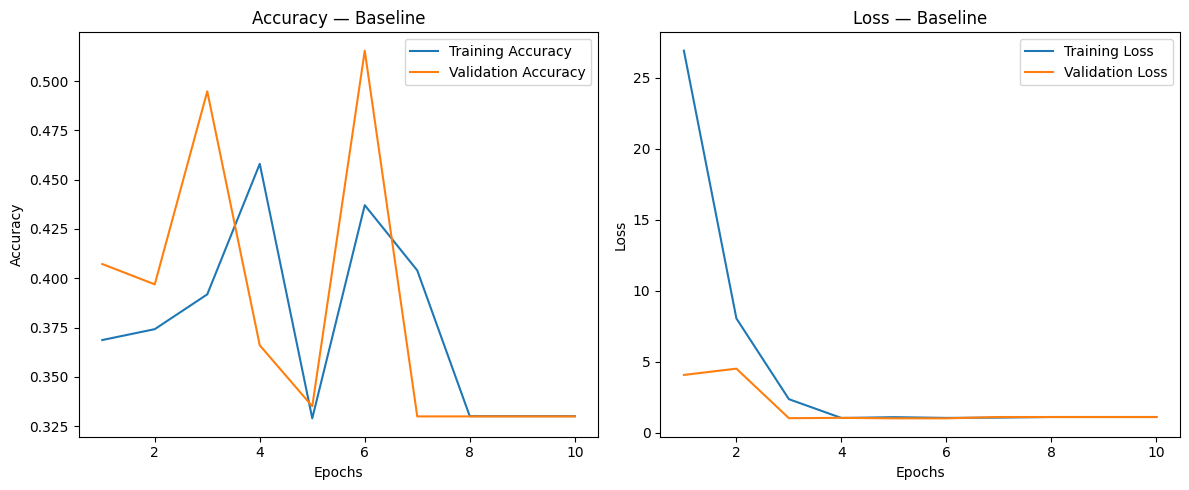

Best val_loss: 1.0060 (epoch 6) | Best val_accuracy: 0.5155


In [19]:
baseline_history = baseline_model.fit(
    train_generator, epochs=10, validation_data=validation_generator,
    class_weight=class_weight, callbacks=get_callbacks(4), verbose=1)
plot_history(baseline_history.history, "Baseline")

### 3.2 CNN v1 — Plain Architecture

In [24]:
cnn_model = models.Sequential([
    layers.Input(shape=(img_height, img_width, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])
cnn_model.compile(loss=categorical_crossentropy, optimizer=Adam(1e-3), metrics=METRICS)
cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,489,987 (9.50 MB)

 Trainable params: 2,489,987 (9.50 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.3918 - loss: 1.1389 - val_accuracy: 0.3763 - val_loss: 1.0651 - learning_rate: 0.0010
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.4238 - loss: 1.0754 - val_accuracy: 0.4897 - val_loss: 0.9910 - learning_rate: 0.0010
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.6236 - loss: 0.8500 - val_accuracy: 0.6959 - val_loss: 0.7686 - learning_rate: 0.0010
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.6468 - loss: 0.8109 - val_accuracy: 0.7062 - val_loss: 0.7296 - learning_rate: 0.0010
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.6987 - loss: 0.7162 - val_accuracy: 0.6701 - val_loss: 0.7794 - learning_rate: 0.0010
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.7196 - loss: 0.6582 - val_accuracy: 0.7010 - val_loss: 0.6996 - learning_rate: 0.0010
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.7020 - loss: 0.6704 - val_accuracy: 

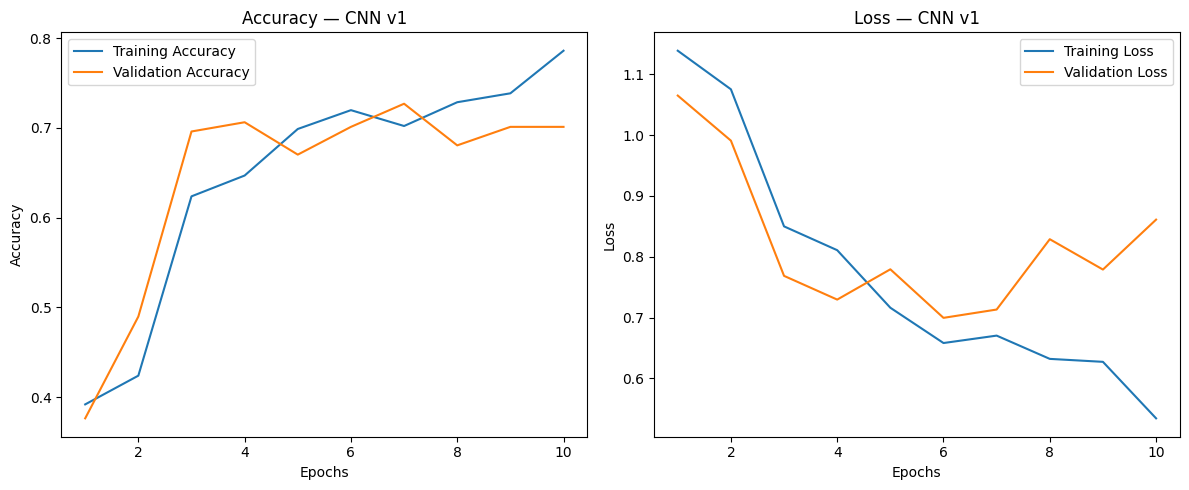

Best val_loss: 0.6996 (epoch 6) | Best val_accuracy: 0.7268


In [25]:
Cnn = cnn_model.fit(
    train_generator, epochs=10, validation_data=validation_generator,
    class_weight=class_weight, callbacks=get_callbacks(5), verbose=1)
plot_history(Cnn.history, "CNN v1")

### 3.3 CNN v2 — Deeper, Regularized Configuration
Two `Conv2D` layers per block + `BatchNormalization`, progressive `Dropout`, `L2` weight decay and `GlobalAveragePooling2D` (far fewer parameters than `Flatten`) to reduce overfitting and validation loss.

In [22]:
def conv_block(x, filters, drop):
    for _ in range(2):
        x = layers.Conv2D(filters, (3, 3), padding="same", use_bias=False,
                          kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    return layers.Dropout(drop)(x)

inp = layers.Input(shape=(img_height, img_width, 3))
x = inp
for f, d in [(32, 0.10), (64, 0.20), (128, 0.25), (256, 0.30)]:
    x = conv_block(x, f, d)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
x = layers.Dropout(0.5)(x)
out = layers.Dense(n_classes, activation="softmax")(x)

cnn_model_v2 = models.Model(inp, out, name="cnn_v2")
cnn_model_v2.compile(loss=categorical_crossentropy, optimizer=Adam(1e-3), metrics=METRICS)
cnn_model_v2.summary()

Model: "cnn_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,419 (4.61 MB)

 Trainable params: 1,206,499 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 172s 6s/step - accuracy: 0.5585 - loss: 1.1355 - val_accuracy: 0.3351 - val_loss: 1.8271 - learning_rate: 0.0010
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 160s 6s/step - accuracy: 0.6711 - loss: 0.8588 - val_accuracy: 0.3351 - val_loss: 2.7959 - learning_rate: 0.0010
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7064 - loss: 0.7890
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
29/29 ━━━━━━━━━━━━━━━━━━━━ 169s 6s/step - accuracy: 0.6909 - loss: 0.8248 - val_accuracy: 0.3608 - val_loss: 3.5265 - learning_rate: 0.0010
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 152s 5s/step - accuracy: 0.7108 - loss: 0.7740 - val_accuracy: 0.4227 - val_loss: 3.0763 - learning_rate: 5.0000e-04
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6704 - loss: 0.8043
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
29/29 ━━━━━━━━━━━━━━━━━━━━ 167s 6s/step - accuracy: 0.6987 - loss: 0.7713 - val_accur

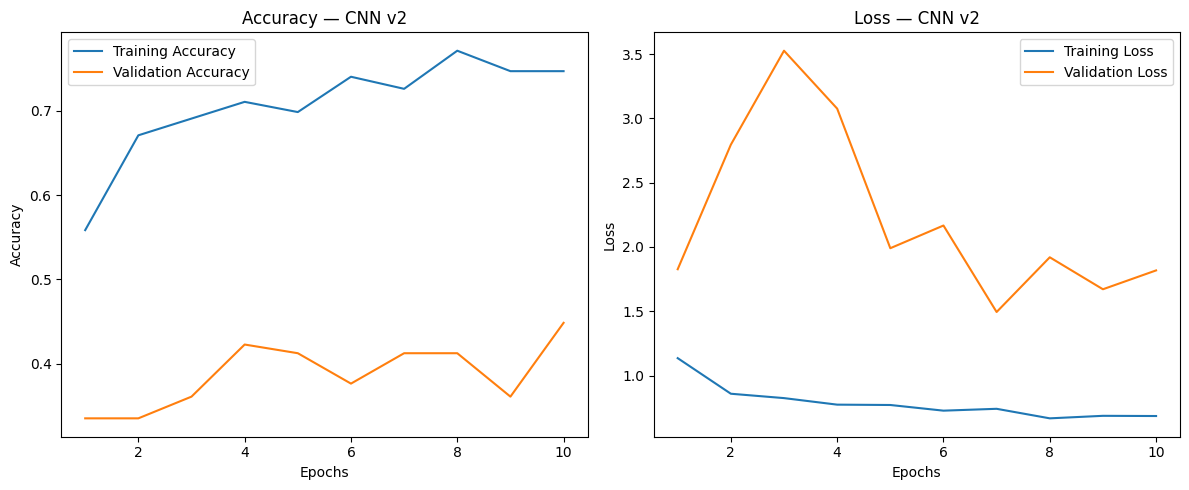

Best val_loss: 1.4944 (epoch 7) | Best val_accuracy: 0.4485


In [23]:
Cnn_v2 = cnn_model_v2.fit(
    train_generator, epochs=10, validation_data=validation_generator,
    class_weight=class_weight, callbacks=get_callbacks(8), verbose=1)
plot_history(Cnn_v2.history, "CNN v2")

### 3.4 CNN v3 — Transfer Learning with MobileNetV2 (best accuracy / lowest val loss)

Two phases: **(1)** backbone frozen, train only the new head (`lr=1e-3`); **(2)** unfreeze the top ~40 backbone layers and fine-tune with `lr=1e-5` (BatchNorm layers stay frozen). Generators give `[0,1]` pixels, so a `Rescaling` layer maps them to `[-1,1]` as MobileNetV2 expects.

> Needs internet on first run to download the ImageNet weights.

In [26]:
from tensorflow.keras.applications import MobileNetV2

base = MobileNetV2(input_shape=(img_height, img_width, 3), include_top=False, weights="imagenet")
base.trainable = False

inp = layers.Input(shape=(img_height, img_width, 3))
x = layers.Rescaling(2.0, offset=-1.0)(inp)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(n_classes, activation="softmax")(x)

tl_model = models.Model(inp, out, name="mobilenetv2_bin")
tl_model.compile(loss=categorical_crossentropy, optimizer=Adam(1e-3), metrics=METRICS)
tl_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 534s 57us/step


Model: "mobilenetv2_bin"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,345,283 (8.95 MB)

 Trainable params: 84,739 (331.01 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [27]:
# Phase 1: train the head only
tl_hist1 = tl_model.fit(
    train_generator, epochs=15, validation_data=validation_generator,
    class_weight=class_weight, callbacks=get_callbacks(4), verbose=1)

Epoch 1/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.6468 - loss: 0.9813 - val_accuracy: 0.7938 - val_loss: 0.5114 - learning_rate: 0.0010
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.7969 - loss: 0.5653 - val_accuracy: 0.8144 - val_loss: 0.4192 - learning_rate: 0.0010
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.8179 - loss: 0.4980 - val_accuracy: 0.8351 - val_loss: 0.3767 - learning_rate: 0.0010
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.8377 - loss: 0.4648 - val_accuracy: 0.8763 - val_loss: 0.3500 - learning_rate: 0.0010
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.8598 - loss: 0.4110 - val_accuracy: 0.8763 - val_loss: 0.3296 - learning_rate: 0.0010
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.8532 - loss: 0.3986 - val_accuracy: 0.9021 - val_loss: 0.3066 - learning_rate: 0.0010
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.8642 - loss: 0.3382 - val_accuracy: 

In [ ]:
# Phase 2: fine-tune the top layers with a tiny learning rate
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

tl_model.compile(loss=categorical_crossentropy, optimizer=Adam(1e-5), metrics=METRICS)
tl_hist2 = tl_model.fit(
    train_generator, epochs=30, validation_data=validation_generator,
    class_weight=class_weight, callbacks=get_callbacks(6), verbose=1)

tl_history = {k: tl_hist1.history[k] + tl_hist2.history[k] for k in tl_hist1.history if k in tl_hist2.history}
plot_history(tl_history, "CNN v3 (MobileNetV2, 2 phases)")

Epoch 1/30
18/29 ━━━━━━━━━━━━━━━━━━━━ 10s 910ms/step - accuracy: 0.9135 - loss: 0.2658

## 4. Model Comparison

All four models are compared on train / validation / test results. The **final model is chosen by lowest validation loss**, so the test set stays untouched until the final report.

In [ ]:
models_dict = {
    "Baseline (Dense)": baseline_model,
    "CNN v1": cnn_model,
    "CNN v2 (BN + Dropout + L2)": cnn_model_v2,
    "CNN v3 (MobileNetV2)": tl_model,
}

rows = []
for name, m in models_dict.items():
    tr_loss, tr_acc = m.evaluate(train_generator, verbose=0)
    va_loss, va_acc = m.evaluate(validation_generator, verbose=0)
    te_loss, te_acc = m.evaluate(test_generator, verbose=0)
    rows.append([name, tr_acc, va_acc, te_acc, va_loss, te_loss])

comparison_df = pd.DataFrame(rows, columns=["Model", "Train Accuracy", "Val Accuracy", "Test Accuracy", "Val Loss", "Test Loss"])
comparison_df.round(4)

In [ ]:
plt.figure(figsize=(11, 5))
x = np.arange(len(comparison_df)); w = 0.27
plt.bar(x - w, comparison_df["Train Accuracy"], w, label="Train")
plt.bar(x,     comparison_df["Val Accuracy"],   w, label="Validation")
plt.bar(x + w, comparison_df["Test Accuracy"],  w, label="Test")
plt.xticks(x, comparison_df["Model"], rotation=15); plt.ylabel("Accuracy")
plt.ylim(max(0, comparison_df[["Train Accuracy","Val Accuracy","Test Accuracy"]].min().min() - 0.05), 1.0)
plt.title("Model Comparison: Train vs Validation vs Test Accuracy"); plt.legend()
plt.tight_layout(); plt.show()

best_idx = comparison_df["Val Loss"].idxmin()
best_model_name = comparison_df.loc[best_idx, "Model"]
print("Best model (lowest validation loss):", best_model_name)

In [ ]:
final_model = list(models_dict.values())[best_idx]
print("Using final_model:", best_model_name)

## 5. Error Analysis — Confusion Matrix & Classification Report

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
import seaborn as sns

test_generator.reset()
y_pred_probs = final_model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes

cm = confusion_matrix(y_true, y_pred)
size = max(6, n_classes * 0.9)
plt.figure(figsize=(size + 1, size))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.title("Confusion Matrix — Final Model (Test)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

print(classification_report(y_true, y_pred, target_names=class_labels, digits=3))

if n_classes == 2:
    print("Test ROC-AUC:", round(roc_auc_score(y_true, y_pred_probs[:, 1]), 4))
else:
    print("Test ROC-AUC (macro, one-vs-rest):", round(roc_auc_score(y_true, y_pred_probs, multi_class="ovr", average="macro"), 4))

In [ ]:
# Look at some misclassified test images
wrong = np.where(y_pred != y_true)[0]
print(f"{len(wrong)} misclassified out of {len(y_true)}")
if len(wrong):
    plt.figure(figsize=(15, 3.5))
    for i, idx in enumerate(wrong[:6]):
        plt.subplot(1, 6, i+1)
        plt.imshow(Image.open(test_data["image_path"][idx]).convert("RGB")); plt.axis("off")
        plt.title(f"true: {class_labels[y_true[idx]]}\npred: {class_labels[y_pred[idx]]} "
                  f"({y_pred_probs[idx, y_pred[idx]]:.2f})", fontsize=9)
    plt.tight_layout(); plt.show()

## 6. Prediction on a New, Unseen Image

In [ ]:
from tensorflow.keras.preprocessing import image

# Replace with your own image path, e.g. "my_bin.jpg". By default we use one test image.
img_path = test_data["image_path"][0]

img = image.load_img(img_path, target_size=(img_height, img_width))   # same as training
img_array = image.img_to_array(img) / 255.0                           # same normalization
img_array = np.expand_dims(img_array, axis=0)

prediction = final_model.predict(img_array)
prediction

In [ ]:
predicted_class_idx = int(np.argmax(prediction))
predicted_label = class_labels[predicted_class_idx]
print("Predicted Class Index:", predicted_class_idx)
print("Predicted Label:", predicted_label)
print(f"Confidence: {prediction[0][predicted_class_idx]:.2%}")

top = np.argsort(prediction[0])[::-1][:min(3, n_classes)]
print("Top predictions:", [(class_labels[i], round(float(prediction[0][i]), 3)) for i in top])

plt.imshow(Image.open(img_path).convert("RGB")); plt.axis("off")
plt.title(f"{predicted_label} ({prediction[0][predicted_class_idx]:.1%})"); plt.show()

**Save the final model**

In [ ]:
final_model.save("bin_classifier_final.keras")
print("Saved: bin_classifier_final.keras")
# Reload later with: keras.models.load_model("bin_classifier_final.keras")

## 7. Conclusion

**Summary of results**
- Four models were trained and compared: a Dense **baseline**, a plain **CNN v1**, a regularized **CNN v2** (BatchNorm + Dropout + L2 + Global Average Pooling) and a **transfer-learning CNN v3** (MobileNetV2, frozen then fine-tuned).
- The table and chart in Section 4 give the numbers for your run. CNNs are expected to clearly beat the Dense baseline, and MobileNetV2 is expected to give the highest accuracy and lowest validation loss. `final_model` is selected automatically by lowest validation loss.
- Validation loss was kept low with regularization, augmentation on training data only, class weights, and `EarlyStopping` / `ReduceLROnPlateau` with best-weight restoring.

**Where the model struggles (see confusion matrix & misclassified images)**
- Errors usually occur between visually similar classes and on blurry, dark, cluttered or partially hidden images.

**Limitations**
- Results depend on the size and variety of the dataset; small classes are more likely to be under-learned (check Section 1 class balance).
- Only a single hold-out test split was used; k-fold cross-validation would give a more robust estimate.
- Images are resized to 128×128, which may lose fine detail.

**Next steps**
- Try higher resolution (160–224 px) and larger backbones (EfficientNetB0, ResNet50).
- Collect more images for weak classes or use stronger augmentation / class-balanced sampling.
- Run a hyperparameter search (Keras Tuner) and test-time augmentation.
- Deploy the final model behind a simple inference script / API.